# CLEF-Flash vs Jev vs Laya vs CLM

## Fair SystemOne decision-model benchmark

All four providers answered **identical native `/v1/systemone` requests** on five suites: Banking77 inbox triage, Amazon ESCI reranking, MMLU, a 90-case model-routing set, and the 200-case BFCL v3 multiple tool-selection split.

### Headline results

| Benchmark (metric) | CLEF-Flash | Jev | Laya | CLM | Chance / random |
|---|---:|---:|---:|---:|---:|
| Banking77 inbox triage (accuracy) | **93.5%** | 80.5% | 45.5% | 1.3% | 1.3% |
| Amazon ESCI reranking (nDCG@10) | 0.9139 | **0.9183** | 0.8553 | 0.8012 | 0.7940 |
| MMLU (accuracy) | 92.5% | **93.5%** | 34.5% | 29.5% | 25.0% |
| Model routing (accuracy) | 96.7% | **97.8%** | 47.8% | 35.6% | 33.3% |
| BFCL tool selection (accuracy) | 98.5% | **100.0%** | 94.0% | 65.5% | — |

**Reading the table.** CLEF-Flash and Jev form a clear top tier. CLEF-Flash leads Jev significantly on Banking77; Jev is slightly ahead on the other four suites, but none of those margins is significant after Holm correction. Both are significantly ahead of Laya and CLM on every suite. Laya is significantly ahead of CLM on Banking77, ESCI, and BFCL; Laya and CLM are not distinguishable on MMLU or routing, where both are close to chance.

### Fairness protocol

- **Same requests:** every provider receives the same `state`, `questions`, option text, and deterministic option order. The only provider-specific fields are each vendor's own model id and, for Laya, its documented token-budget fields (below).
- **Same client:** one sequential request at a time, 120 s timeout, 3 attempts with identical backoff, and one warm-up request that is not part of any dataset (so no server-side cache can answer a measured case).
- **Fresh servers, same GPU:** the three local models ran one at a time on the same RTX 4090 (GPU 1), each from a freshly restarted server. Jev ran remotely in the same session.
- **Vendor-recommended configuration:** Laya ran through its official `laya.serve` app with the Router choosing the checkpoint (English for all of these English inputs) and `head_max_len=1024`, `max_len=2048`, the smallest budget at which Laya reports no merged options on Banking77's 77 labels. CLM ran with `clm-serve` and the Qwen3-8B pooling encoder exactly as its model card documents. CLEF-Flash ran through its native SystemOne decision head.
- **Multiple comparisons:** six pairwise tests per suite, Holm-adjusted within each suite.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    raise FileNotFoundError("Run this notebook from the repository root.")

PROVIDERS = ["clef-flash", "jev", "laya", "clm"]
COLORS = {"clef-flash": "#f48120", "jev": "#355c9a", "laya": "#2a9d8f", "clm": "#8e6bbf"}
FIGURES = ROOT / "figures"
TABLES = ROOT / "tables"
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

def save_figure(fig, name):
    for suffix in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{suffix}", dpi=200, bbox_inches="tight")

def save_table(frame, name, index=True):
    frame.to_csv(TABLES / f"{name}.csv", index=index)
    return frame

public = pd.read_csv(ROOT / "results/public_benchmarks/summary.csv")
public_analysis = json.loads((ROOT / "results/public_benchmarks/analysis.json").read_text())
routing = pd.read_csv(ROOT / "results/model_routing/summary.csv").set_index("provider")
tools = pd.read_csv(ROOT / "results/tool_selection/summary.csv").set_index("provider")

def suite_metric(suite, metric):
    return public[public["suite"] == suite].set_index("provider")[metric]

primary = pd.DataFrame({
    "Banking77 accuracy": suite_metric("inbox_triage", "accuracy"),
    "ESCI nDCG@10": suite_metric("reranking", "ndcg_at_10"),
    "MMLU accuracy": suite_metric("llm_evals", "accuracy"),
    "Routing accuracy": routing["accuracy"],
    "BFCL accuracy": tools["accuracy"],
}).loc[PROVIDERS]
save_table(primary, "primary_metrics").round(4)

,Banking77 accuracy,ESCI nDCG@10,MMLU accuracy,Routing accuracy,BFCL accuracy
provider,,,,,
clef-flash,0.9351,0.9139,0.925,0.9667,0.985
jev,0.8052,0.9183,0.935,0.9778,1.000
laya,0.4545,0.8553,0.345,0.4778,0.940
clm,0.0130,0.8012,0.295,0.3556,0.655


## Primary quality metrics

Higher is better. Dashed lines mark chance accuracy (Banking77 1/77, MMLU 1/4, routing 1/3) or the simulated random-permutation nDCG@10 for ESCI.

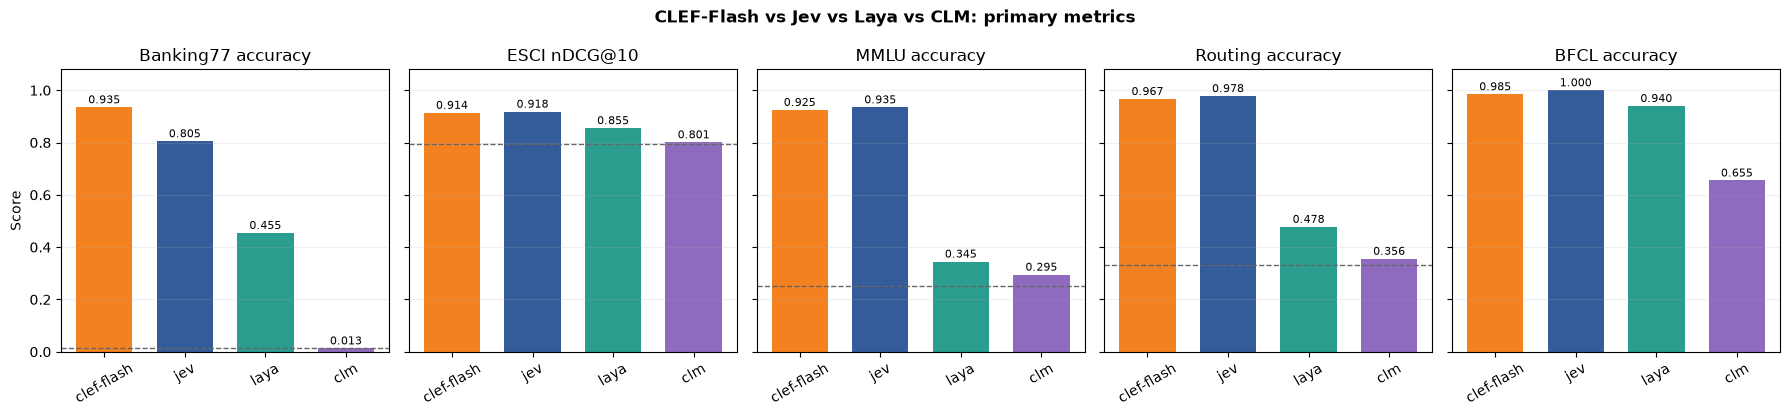

In [2]:
baselines = {
    "Banking77 accuracy": public_analysis["baselines"]["inbox_triage_accuracy"],
    "ESCI nDCG@10": public_analysis["baselines"]["reranking_random_permutation"]["ndcg_at_10"],
    "MMLU accuracy": public_analysis["baselines"]["llm_evals_accuracy"],
    "Routing accuracy": 1 / 3,
    "BFCL accuracy": None,
}
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2), sharey=True)
for axis, column in zip(axes, primary.columns):
    values = primary[column]
    bars = axis.bar(PROVIDERS, values, color=[COLORS[p] for p in PROVIDERS], width=0.7)
    if baselines[column] is not None:
        axis.axhline(baselines[column], color="#666", linestyle="--", linewidth=1)
    axis.set_title(column)
    axis.set_ylim(0, 1.08)
    axis.grid(axis="y", alpha=0.2)
    axis.tick_params(axis="x", rotation=30)
    for bar, value in zip(bars, values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.3f}", ha="center", fontsize=8)
axes[0].set_ylabel("Score")
fig.suptitle("CLEF-Flash vs Jev vs Laya vs CLM: primary metrics", fontweight="bold")
fig.tight_layout()
save_figure(fig, "primary_metrics")
plt.show()

## Paired significance tests

Classification suites use the exact two-sided McNemar test on per-case correctness; ESCI uses a paired 20,000-sample bootstrap over query-level nDCG@10. `p_holm` is Holm-adjusted across the six provider pairs within each suite. `left_correct_right_wrong` and `left_wrong_right_correct` count the discordant cases.

In [3]:
def load_pairs(path, suite=None):
    frame = pd.read_csv(ROOT / path)
    if suite is not None:
        frame.insert(0, "suite", suite)
    return frame

classification_pairs = pd.concat([
    load_pairs("results/public_benchmarks/classification_pairwise.csv"),
    load_pairs("results/model_routing/classification_pairwise.csv", "model_routing"),
    load_pairs("results/tool_selection/classification_pairwise.csv", "tool_selection"),
], ignore_index=True)
classification_pairs["significant_holm_0.05"] = classification_pairs["p_holm"] < 0.05
save_table(classification_pairs, "pairwise_classification_mcnemar", index=False)
display(classification_pairs[[
    "suite", "left", "right", "left_correct_right_wrong", "left_wrong_right_correct",
    "p_exact_two_sided", "p_holm", "significant_holm_0.05",
]])

reranking_pairs = load_pairs("results/public_benchmarks/reranking_pairwise.csv")
reranking_pairs["significant_holm_0.05"] = reranking_pairs["p_holm"] < 0.05
save_table(reranking_pairs, "pairwise_reranking_bootstrap", index=False)
display(reranking_pairs)

,suite,left,right,left_correct_right_wrong,left_wrong_right_correct,p_exact_two_sided,p_holm,significant_holm_0.05
0,inbox_triage,clef-flash,clm,142,0,3.587324e-43,2.152394e-42,True
1,inbox_triage,clef-flash,jev,21,1,1.096725e-05,1.096725e-05,True
2,inbox_triage,clef-flash,laya,75,1,2.038173e-21,8.152692e-21,True
3,inbox_triage,clm,jev,0,122,3.761582e-37,1.880791e-36,True
4,inbox_triage,clm,laya,2,70,1.113425e-18,3.340274e-18,True
5,inbox_triage,jev,laya,59,5,9.002817e-13,1.800563e-12,True
6,llm_evals,clef-flash,clm,129,3,1.408532e-34,7.042662e-34,True
7,llm_evals,clef-flash,jev,9,11,8.238029e-01,8.238029e-01,False
8,llm_evals,clef-flash,laya,119,3,1.138796e-31,3.416389e-31,True
9,llm_evals,clm,jev,0,128,5.877472e-39,3.526483e-38,True


,left,right,mean_difference,ci95_low,ci95_high,bootstrap_two_sided_p,p_holm,significant_holm_0.05
0,clef-flash,clm,0.112705,0.075386,0.152022,0.0000,0.0000,True
1,clef-flash,jev,-0.004415,-0.042229,0.028183,0.8404,0.8404,False
2,clef-flash,laya,0.058592,0.021005,0.096522,0.0015,0.0045,True
3,clm,jev,-0.117120,-0.166365,-0.072121,0.0000,0.0000,True
4,clm,laya,-0.054113,-0.103612,-0.008208,0.0185,0.0370,True
5,jev,laya,0.063008,0.027751,0.098784,0.0006,0.0024,True


## Calibration and latency

Lower log loss and Brier score are better. Latency is client-side wall-clock time per request (p50). The three local models ran on the same GPU over loopback; **Jev's latency includes the network round trip to its hosted API**, so it is not directly comparable.

In [4]:
rows = []
for suite in ("inbox_triage", "llm_evals", "reranking"):
    frame = public[public["suite"] == suite].set_index("provider")
    for provider in PROVIDERS:
        rows.append({
            "suite": suite, "provider": provider,
            "log_loss": frame.loc[provider, "log_loss"],
            "brier_score": frame.loc[provider, "brier_score"],
            "latency_p50_ms": frame.loc[provider, "latency_p50_ms"],
        })
for suite, frame in (("model_routing", routing), ("tool_selection", tools)):
    for provider in PROVIDERS:
        rows.append({
            "suite": suite, "provider": provider,
            "log_loss": frame.loc[provider, "log_loss"],
            "brier_score": frame.loc[provider, "brier_score"],
            "latency_p50_ms": frame.loc[provider, "latency_p50_ms"],
        })
quality = pd.DataFrame(rows)
save_table(quality, "calibration_and_latency", index=False)
for metric, digits in (("latency_p50_ms", 1), ("log_loss", 3), ("brier_score", 3)):
    pivot = quality.pivot(index="suite", columns="provider", values=metric)[PROVIDERS]
    display(save_table(pivot, metric).round(digits))

provider,clef-flash,jev,laya,clm
suite,,,,
inbox_triage,322.6,327.2,16.3,25.7
llm_evals,69.1,315.5,8.4,61.3
model_routing,86.2,309.4,9.0,28.2
reranking,309.0,312.3,19.5,66.8
tool_selection,102.5,312.0,8.9,68.7


provider,clef-flash,jev,laya,clm
suite,,,,
inbox_triage,0.274,1.998,8.766,5.880
llm_evals,0.244,0.456,1.393,2.575
model_routing,0.226,0.067,0.909,1.707
reranking,NaN,NaN,NaN,NaN
tool_selection,0.050,0.003,0.229,0.999


provider,clef-flash,jev,laya,clm
suite,,,,
inbox_triage,0.094,0.291,0.954,1.123
llm_evals,0.111,0.112,0.758,1.050
model_routing,0.093,0.038,0.550,0.888
reranking,NaN,NaN,NaN,NaN
tool_selection,0.013,0.001,0.113,0.526


## MMLU subject breakdown

Each subject has 20 questions, so per-subject differences are noisy.

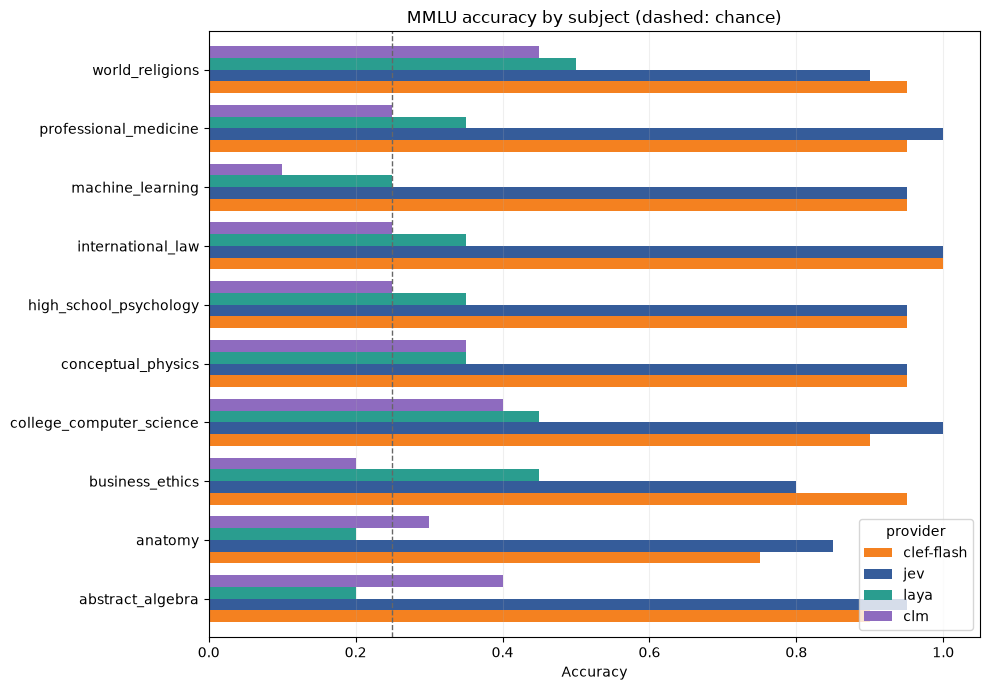

In [5]:
subjects = pd.read_csv(ROOT / "results/public_benchmarks/mmlu_by_subject.csv")
subject_plot = subjects.pivot(index="subject", columns="provider", values="accuracy")[PROVIDERS].sort_index()
axis = subject_plot.plot.barh(figsize=(10, 7), color=[COLORS[p] for p in PROVIDERS], width=0.8)
axis.axvline(0.25, color="#666", linestyle="--", linewidth=1)
axis.set_xlabel("Accuracy")
axis.set_ylabel("")
axis.set_xlim(0, 1.05)
axis.set_title("MMLU accuracy by subject (dashed: chance)")
axis.grid(axis="x", alpha=0.2)
plt.tight_layout()
save_figure(axis.get_figure(), "mmlu_by_subject")
save_table(subject_plot, "mmlu_by_subject")
plt.show()

## Model routing by tier

90 curated prompts, 30 per expected tier. Per-tier recall shows where each model's routing errors fall.

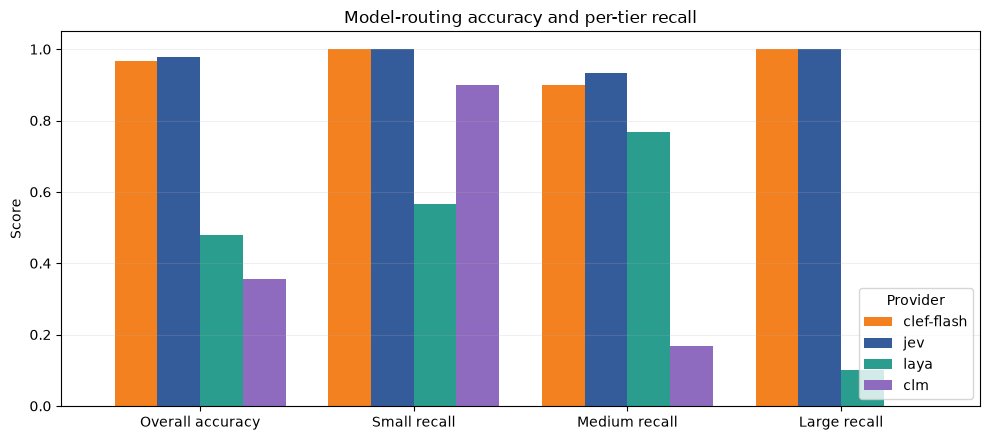

,provider,cases,completed,errors,accuracy,macro_f1,small_recall,medium_recall,large_recall,latency_p50_ms,latency_p95_ms,latency_mean_ms,log_loss,brier_score,ece
0,clef-flash,90,90,0,0.966667,0.966583,1.000000,0.900000,1.0,86.249424,86.635632,86.270189,0.226167,0.093289,0.140357
1,jev,90,90,0,0.977778,0.977753,1.000000,0.933333,1.0,309.418899,400.181235,325.584969,0.066842,0.037756,0.044000
2,laya,90,90,0,0.477778,0.438261,0.566667,0.766667,0.1,8.967690,9.419825,9.037332,0.909478,0.550193,0.149176
3,clm,90,90,0,0.355556,0.249033,0.900000,0.166667,0.0,28.156313,30.179817,28.621453,1.707083,0.887598,0.358498


,provider,cases,completed,errors,accuracy,macro_f1,latency_p50_ms,latency_p95_ms,latency_mean_ms,log_loss,brier_score,ece
0,clef-flash,200,200,0,0.985,0.984456,102.539599,140.368681,107.302562,0.050002,0.012933,0.044921
1,jev,200,200,0,1.000,1.000000,311.963061,408.371395,328.240436,0.002652,0.000552,0.002500
2,laya,200,200,0,0.940,0.936097,8.916070,9.589623,8.949598,0.228947,0.113197,0.113798
3,clm,200,200,0,0.655,0.634542,68.698516,74.755759,66.701132,0.999492,0.526252,0.157795


In [6]:
tier = routing.loc[PROVIDERS, ["accuracy", "small_recall", "medium_recall", "large_recall"]].T
axis = tier.plot.bar(figsize=(10, 4.5), color=[COLORS[p] for p in PROVIDERS], width=0.8)
axis.set_ylim(0, 1.05)
axis.set_ylabel("Score")
axis.set_title("Model-routing accuracy and per-tier recall")
axis.set_xticklabels(["Overall accuracy", "Small recall", "Medium recall", "Large recall"], rotation=0)
axis.grid(axis="y", alpha=0.2)
axis.legend(title="Provider", loc="lower right")
plt.tight_layout()
save_figure(axis.get_figure(), "routing_by_tier")
plt.show()
display(save_table(routing.loc[PROVIDERS].reset_index(), "routing_summary", index=False))
display(save_table(tools.loc[PROVIDERS].reset_index(), "tool_selection_summary", index=False))

## Conclusions

- **CLEF-Flash vs Jev:** CLEF-Flash is significantly better on Banking77 (93.5% vs 80.5%). Jev is slightly ahead on ESCI, MMLU, routing, and BFCL, but none of those margins is significant after Holm correction.
- **Laya:** strongest of the two small models on Banking77, ESCI, and BFCL (94.0% tool selection), and by far the fastest (about 8–20 ms p50). It is close to chance on MMLU (34.5%) and routing (47.8%), tasks that need knowledge or reasoning about difficulty rather than matching text to a label.
- **CLM (zero-shot checkpoint):** at chance on Banking77, where it predicted only two of 77 intents, and close to chance on MMLU, routing, and ESCI. Its best result is BFCL tool selection (65.5%).

## Caveats

- **Diagnostic subsets:** Banking77 has two examples per intent, ESCI reranks ten sampled products per query, MMLU covers ten of 57 subjects, routing labels are curated judgments, and BFCL is scored on function-name selection only. None of these are official leaderboard scores.
- **ESCI floor:** 218 of the 500 sampled products are `Exact`, so a random ordering already scores nDCG@10 0.794; CLM's 0.801 is close to random.
- **Routing option order:** the routing question always lists small, medium, large in that order (other suites shuffle options per case). Every provider saw the same order, but position bias is not controlled.
- **Laya:** the token budget was raised beyond its default (192/512) following Laya's guidance for many-option questions; default settings would score lower on Banking77. Laya's checkpoint warns that its calibration temperature for choices with 11+ options is invalid and was clamped, so its Banking77 probabilities are uncalibrated.
- **CLM:** its model card states that the published agentic results use fine-tuned heads, not this zero-shot checkpoint. Reproducing the card's own example gives the same decision but a probability of 0.988 instead of the documented 0.939, so a small encoder numerics difference cannot be ruled out.
- **Jev:** a hosted model whose version can change; Banking77 moved from 79.2% in the earlier two-way run to 80.5% here, while CLEF-Flash reproduced exactly.
- **Latency:** Jev's figures include network time; local figures depend on this GPU and on request size (Banking77 sends 77 options, BFCL sends full parameter schemas).

## Reproduce

```bash
python3 -m pip install -r requirements.txt
python3 scripts/analyze_public_benchmarks.py
python3 -m pytest -q
python3 scripts/build_results_notebook.py
jupyter nbconvert --to notebook --execute --inplace decision_model_benchmarks_results.ipynb
```

Executing the notebook writes every figure to `figures/` (PNG and PDF) and every table to `tables/` (CSV).

To rerun inference, configure `.env`, start one local server at a time on the same GPU, and run each runner for that provider, for example:

```bash
python3 scripts/run_public_benchmarks.py --providers laya --force
python3 scripts/run_model_routing.py --providers laya --force
python3 scripts/run_tool_selection.py --providers laya --force
```